Attempting to see if my mental model for using high-beta softmax is about correct. The idea being that feature neurons in some initial state influence the memory neurons, which then correct the feature neurons to whatever memory neuron "won"

In [2]:
import scipy.integrate as int
import matplotlib.pyplot as plt
import numpy as np

In [3]:
#We are going to define activation functions for feature and memory separately
beta_feature = 10 #Sharpness of the tanh activation
def f_feature(xvec):
    return np.tanh(beta_feature*xvec) #Shift and scale to [0,1]

beta_memory = 100 #Sharpness of the softmax activation function
def f_memory(x, axis=-1):
    # Subtract max for numerical stability along the specified axis
    x_max = np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(beta_memory*(x - x_max))
    
    # Divide by the sum of exponentials along the same axis
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)



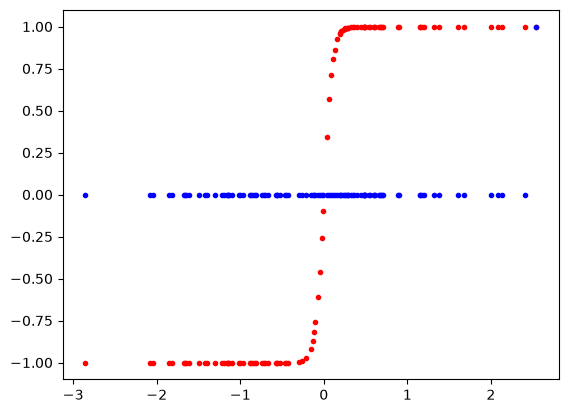

In [4]:
#Test these activation functions out on random numbers
rands = np.random.standard_normal(100)
plt.plot(rands,f_feature(rands),'r.')
plt.plot(rands,f_memory(rands),'b.')

In [19]:
#Binary error correction task, so rows are target code words. 
#nColumns is the number of features, nRows is the number of memories

codewordMatrix = np.asarray([[1,1,1],
                                [-1,-1,-1]])
nFeatures = np.shape(codewordMatrix)[1]
nMemories = np.shape(codewordMatrix)[0]

#Construct the array of rhs functions
#NOTE: DEFAULT ARGUMENT TRICK REQUIRED TO BAKE IN CORRECT NUMBERS IN PYTHON
rhs = []
for i in range(nFeatures):
    rhs.append(
        lambda x, ymems, featidx=i: -x + np.dot(np.copy(codewordMatrix[:,featidx]),ymems)
    )
for j in range(nMemories):
    rhs.append(
        lambda x, yfeats, memidx=j: -x + np.dot(np.copy(codewordMatrix[memidx,:]),yfeats)
    )
def odefun(_,statevec):
    yfeats = f_feature(statevec[0:nFeatures])
    ymems = f_memory(statevec[nFeatures:])
    allRHS = np.zeros(np.size(statevec))
    for i in range(nFeatures):
        allRHS[i] = rhs[i](statevec[i],ymems)
    for j in range(nMemories):
        imem = nFeatures + j
        allRHS[imem] = rhs[imem](statevec[imem],yfeats)
        print(np.dot(codewordMatrix[j,:],yfeats))
    return allRHS

#Construct initial values
iVals = np.asarray([1,-1,-1,0,0])

In [20]:
output = int.solve_ivp(odefun,[0,4],iVals,atol=1e-6,rtol=1e-6)

-0.9999999958776927
0.9999999958776927
-0.9999999954238428
0.9999999954238428
-0.999999995670008
0.999999995670008
-0.9999999957398329
0.9999999957398329
-0.9999999962651924
0.9999999962651924
-0.9999999965191995
0.9999999965191995
-0.9999999967595916
0.9999999967595916
-0.9999999966399052
0.9999999966399052
-0.9999999972120203
0.9999999972120203
-0.9999999975918313
0.9999999975918313
-0.9999999997247176
0.9999999997247176
-1.0000000000747695
1.0000000000747695
-1.0000000006793375
1.0000000006793375
-1.0000000008497945
1.0000000008497945
-1.0000000026583367
1.0000000026583367
-1.0000000036811483
1.0000000036811483
-1.000000010178788
1.000000010178788
-1.0000000115839658
1.0000000115839658
-1.0000000135383653
1.0000000135383653
-1.0000000136054394
1.0000000136054394
-1.0000000216499245
1.0000000216499245
-1.000000026575317
1.000000026575317
-1.000000065472043
1.000000065472043
-1.0000000757767924
1.0000000757767924
-1.0000000905803428
1.0000000905803428
-1.0000000905512803
1.00000009055

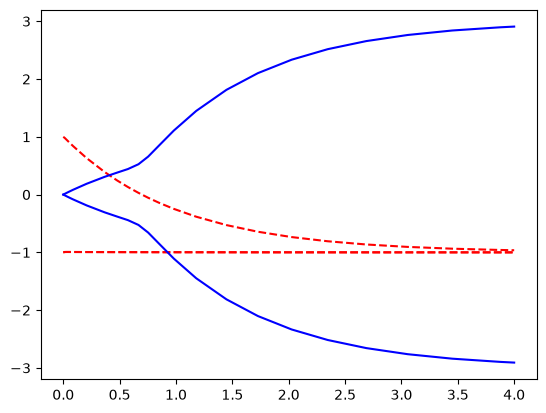

In [21]:
plt.plot(output.t,output.y[0:nFeatures].T,'r--')
plt.plot(output.t,output.y[nFeatures:].T,'b-')